# CINE–APD cell dataset

This notebook creates one crop per tracked cell, corrects APD-to-CINE clock drift, and assigns detected APD peaks globally one-to-one. Track-quality flags remain available for review but only a missing complete crop blocks automatic classification.

In [1]:
%matplotlib inline
from pathlib import Path
import json
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile
from IPython.display import display, Image as DisplayImage

import cine_apd_cell_dataset as pipeline
importlib.reload(pipeline)

from cine_apd_cell_dataset import (
    Config, Recording, prepare, load_model, foreground, preview,
    plot_peaks, plot_assignments, export_dataset, reclassify_run,
    apply_manual_assignments, assignment_summary,
    find_suspicious_track_cases, plot_track_case, export_track_case_gif,
)

## Configuration

Edit file paths and the frame range here. `match_padding_ms` is the remaining safety margin after automatic affine clock-drift correction.

In [2]:
cfg = Config()
cfg.cine_path = r"/Volumes/Extreme SSD/Masterarbeit/APD/161026/phantom_NIH3T3_b_HeLa_5.cine"
cfg.apd_path = r"/Volumes/Extreme SSD/Masterarbeit/APD/161026/phantom_NIH3T3_b_HeLa_5.npz"
cfg.output_root = str(Path(cfg.cine_path).parent / "cine_apd_cell_dataset")
cfg.pretrained_model = r"/Volumes/Extreme SSD/Masterarbeit/cellpose/highspeed/models/NIH3T3/models/high_speed_1"

# Frame-to-NI mapping and residual APD delay.
cfg.sync_mode = "trigger"
cfg.active_low = True
cfg.sync_correction_s = 0.371 / 1000
cfg.apd_delay_s = 0.0

# Automatic offset and linear clock-drift correction.
cfg.correct_time_drift = True
cfg.drift_search_ms = 2.0
cfg.drift_min_pairs = 8
cfg.drift_max_ppm = 500.0
cfg.drift_residual_ms = 0.10
cfg.match_padding_ms = 0.50

# Enlarged APD association region: fractional x0, x1, y0, y1.
cfg.detection_roi = (0.05, 0.50, 0.30, 0.85)

# APD peak detection.
cfg.peak_polarity = 1
cfg.peak_height_sigma = 6.0
cfg.peak_prominence_sigma = 4.0
cfg.peak_height_v = 0.2
cfg.peak_min_distance_ms = 0.1
cfg.peak_smooth_ms = 0.0
cfg.peak_interval_rel_height = 0.95

# Tracking and crop extraction.
cfg.flow_axis = "x"
cfg.flow_sign = -1
cfg.max_link_distance_px = 60.0
cfg.track_memory_frames = 1
cfg.min_track_detections = 1
# Cells move about 40 px per frame from right to left in this recording.
cfg.tracking_expected_step_px = 40.0
cfg.tracking_prediction_tolerance_px = 20.0
cfg.tracking_reverse_tolerance_px = 3.0
cfg.tracking_ambiguity_margin_px = 5.0
cfg.close_tracks_at_exit = True
# Mark touching, very large, or elongated masks as clusters.
cfg.cluster_separation_px = 2
cfg.max_cell_area = 800
cfg.max_cell_elongation = 1.8
cfg.reject_cluster_tracks = True
cfg.review_passage_delta_ms = 0.10
cfg.review_close_distance_px = 30.0
cfg.review_split_gap_frames = 3
cfg.review_context_frames = 2
cfg.passage_edge_px = 8
cfg.crop_margin_px = 3
cfg.diameter = 20.0
cfg.min_size = 50
cfg.min_area = 100
cfg.cellprob_threshold = -1.5
cfg.flow_threshold = 0.4
cfg.cellpose_input = "raw"
cfg.screen_z = 5.0
cfg.screen_min_area = 20
cfg.background_samples = 101
cfg.screen_enabled = True

cfg.start_frame = 0
cfg.stop_frame = None # Exclusive; use None for the full recording.

for name in ("cine_path", "apd_path"):
    path = Path(getattr(cfg, name))
    if not path.is_file():
        raise FileNotFoundError(f"{name}: {path}")
if cfg.pretrained_model and not Path(cfg.pretrained_model).is_file():
    raise FileNotFoundError(f"pretrained_model: {cfg.pretrained_model}")
print("Configuration validated.")

Configuration validated.


## Prepare recording

CINE: 2094608 frames, 70000.8 fps; NI: 500000 samples/s
Time mapping: trigger; APD overlap 0.100905 to 29.999998 s


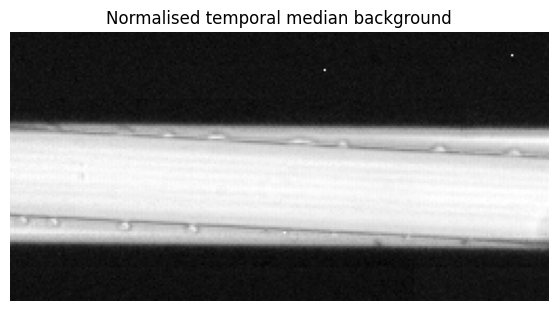

In [3]:
if "rec" in globals():
    rec.close()
rec, background = prepare(cfg)

fig, ax = plt.subplots(figsize=(8, 3), constrained_layout=True)
ax.imshow(background, cmap="gray")
ax.set_title("Normalised temporal median background")
ax.axis("off")
display(fig)
plt.close(fig)

## Adjust and preview the APD voltage cutoff

`MIN_PEAK_HEIGHT_V` is the minimum peak height above the median baseline, in volts. Change it and rerun only the next cell. The red dashed line is the effective threshold. Set `APD_VIEW_S` to a time interval such as `(6.2, 6.8)` for a detailed view.

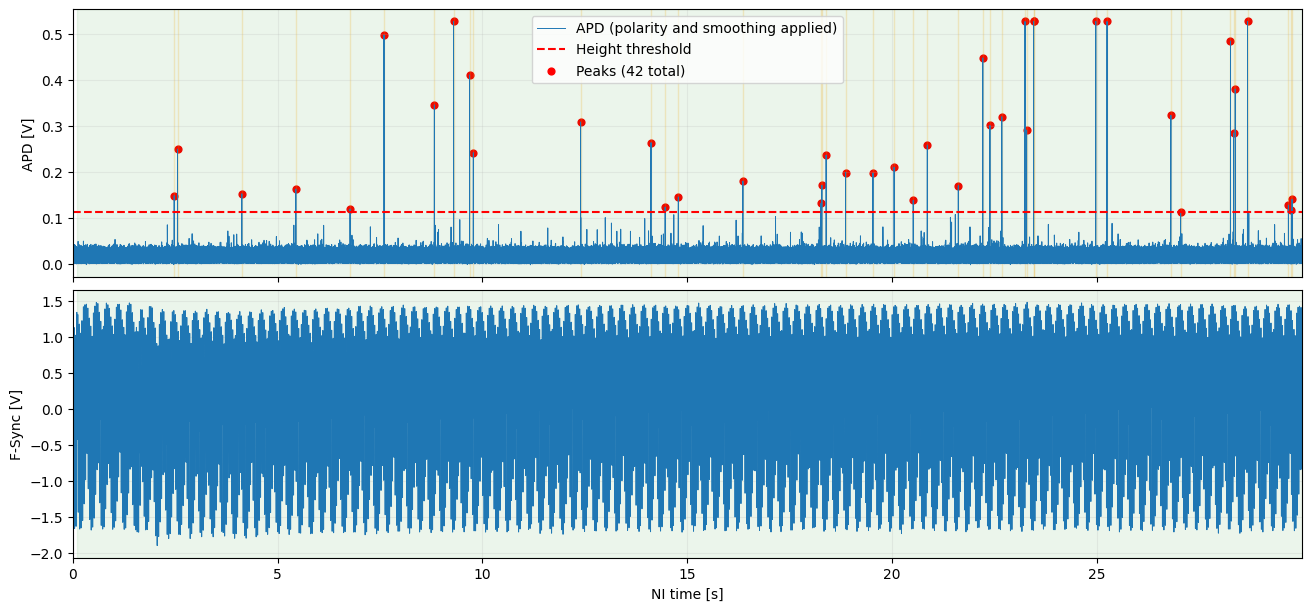

Detected APD peaks: 42


,peak_id,apd_time_s,raw_v,height_v,prominence_v
0,0,2.472962,0.149114,0.135150,0.147845
1,1,2.553876,0.250208,0.236244,0.250598
2,2,4.123830,0.153142,0.139178,0.152211
3,3,5.442868,0.163485,0.149521,0.163134
4,4,6.765878,0.119858,0.105894,0.120184
5,5,7.595212,0.498346,0.484382,0.498769
6,6,8.825452,0.346405,0.332441,0.345603
7,7,9.293176,0.527846,0.513882,0.528768
8,8,9.684670,0.411605,0.397641,0.412318
9,9,9.776590,0.242475,0.228511,0.242060


In [4]:
# EDIT THIS VALUE and rerun this cell until the detected peaks look correct.
MIN_PEAK_HEIGHT_V = 0.10
APD_VIEW_S = None  # Example: (6.2, 6.8); None shows the complete recording.

cfg.peak_height_v = MIN_PEAK_HEIGHT_V
peak_figure, raw_peaks = plot_peaks(rec, cfg, limits=APD_VIEW_S)
display(peak_figure)
plt.close(peak_figure)
print(f"Detected APD peaks: {len(raw_peaks)}")
display(raw_peaks[["peak_id", "apd_time_s", "raw_v", "height_v", "prominence_v"]].head(50))

## Load Cellpose and inspect one frame

Cellpose 4.2.1.1; GPU=True; Model=/Volumes/Extreme SSD/Masterarbeit/cellpose/highspeed/models/NIH3T3/models/high_speed_1
Custom weights must match the installed Cellpose version.


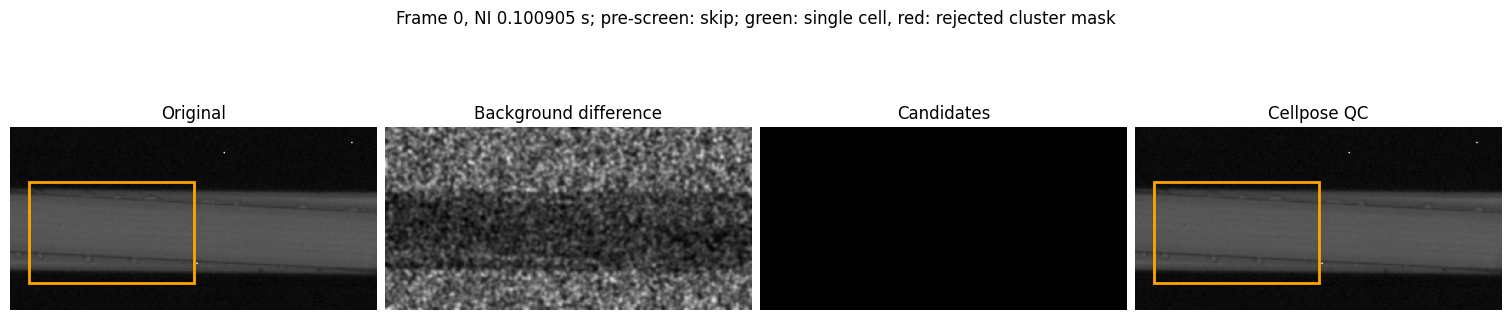

In [5]:
model = load_model(cfg)
PREVIEW_FRAME = None
if PREVIEW_FRAME is None:
    sample_frames = np.unique(np.linspace(rec.start, rec.stop - 1, min(100, rec.stop - rec.start)).astype(int))
    scores = [int(foreground(rec.frame(frame), background, cfg)[1].sum()) for frame in sample_frames]
    PREVIEW_FRAME = int(sample_frames[np.argmax(scores)])
preview_figure = preview(rec, background, model, cfg, PREVIEW_FRAME)
display(preview_figure)
plt.close(preview_figure)

## Run tracking, drift correction, and peak assignment

In [6]:
run_dir, cells_current = export_dataset(rec, background, model, cfg)
run_dir = Path(run_dir)
peaks_current = pd.read_csv(run_dir / "peaks.csv")
cells_final = cells_current.copy()
cells_final.to_csv(run_dir / "cells_final.csv", index=False)
review_rec = rec

alignment_columns = [
    "alignment_status", "alignment_pairs", "alignment_offset_ms",
    "alignment_drift_ppm", "alignment_rmse_ms",
]
display(peaks_current[alignment_columns].drop_duplicates())
category_summary, peak_summary = assignment_summary(cells_current, peaks_current)
display(category_summary)
display(peak_summary)

Frame 0/2094607; Tracks 0
Frame 500/2094607; Tracks 0
Frame 1000/2094607; Tracks 0
Frame 1500/2094607; Tracks 0
Frame 2000/2094607; Tracks 0
Frame 2500/2094607; Tracks 0
Frame 3000/2094607; Tracks 0
Frame 3500/2094607; Tracks 0
Frame 4000/2094607; Tracks 0
Frame 4500/2094607; Tracks 0
Frame 5000/2094607; Tracks 0
Frame 5500/2094607; Tracks 0
Frame 6000/2094607; Tracks 0
Frame 6500/2094607; Tracks 0
Frame 7000/2094607; Tracks 0
Frame 7500/2094607; Tracks 0
Frame 8000/2094607; Tracks 0
Frame 8500/2094607; Tracks 0
Frame 9000/2094607; Tracks 0
Frame 9500/2094607; Tracks 0
Frame 10000/2094607; Tracks 0
Frame 10500/2094607; Tracks 0
Frame 11000/2094607; Tracks 0
Frame 11500/2094607; Tracks 0
Frame 12000/2094607; Tracks 0
Frame 12500/2094607; Tracks 0
Frame 13000/2094607; Tracks 0
Frame 13500/2094607; Tracks 0
Frame 14000/2094607; Tracks 0
Frame 14500/2094607; Tracks 0
Frame 15000/2094607; Tracks 0
Frame 15500/2094607; Tracks 0
Frame 16000/2094607; Tracks 0
Frame 16500/2094607; Tracks 0
Fram

2026-10-19 16:22:48.483 python[58731:8633267] Error creating directory 
 The volume ‚ÄúMacintosh HD‚Äù is out of space. You can‚Äôt save the file ‚Äúmpsgraph-58731-2026-10-19_16_22_48-243681285‚Äù because the volume ‚ÄúMacintosh HD‚Äù is out of space.
2026-10-19 16:22:48.512 python[58731:8633267] Error creating directory 
 The volume ‚ÄúMacintosh HD‚Äù is out of space. You can‚Äôt save the file ‚Äúmpsgraph-58731-2026-10-19_16_22_48-365992262‚Äù because the volume ‚ÄúMacintosh HD‚Äù is out of space.
2026-10-19 16:22:48.521 python[58731:8633267] Error creating directory 
 The volume ‚ÄúMacintosh HD‚Äù is out of space. You can‚Äôt save the file ‚Äúmpsgraph-58731-2026-10-19_16_22_48-2683899866‚Äù because the volume ‚ÄúMacintosh HD‚Äù is out of space.


Frame 1285000/2094607; Tracks 35
Frame 1285500/2094607; Tracks 35
Frame 1286000/2094607; Tracks 35
Frame 1286500/2094607; Tracks 35
Frame 1287000/2094607; Tracks 35
Frame 1287500/2094607; Tracks 35
Frame 1288000/2094607; Tracks 35
Frame 1288500/2094607; Tracks 35
Frame 1289000/2094607; Tracks 35
Frame 1289500/2094607; Tracks 35
Frame 1290000/2094607; Tracks 35
Frame 1290500/2094607; Tracks 35
Frame 1291000/2094607; Tracks 35
Frame 1291500/2094607; Tracks 35
Frame 1292000/2094607; Tracks 35
Frame 1292500/2094607; Tracks 35
Frame 1293000/2094607; Tracks 35
Frame 1293500/2094607; Tracks 35
Frame 1294000/2094607; Tracks 35
Frame 1294500/2094607; Tracks 35
Frame 1295000/2094607; Tracks 35
Frame 1295500/2094607; Tracks 35
Frame 1296000/2094607; Tracks 35
Frame 1296500/2094607; Tracks 35
Frame 1297000/2094607; Tracks 35
Frame 1297500/2094607; Tracks 35
Frame 1298000/2094607; Tracks 35
Frame 1298500/2094607; Tracks 35
Frame 1299000/2094607; Tracks 35
Frame 1299500/2094607; Tracks 35
Frame 1300

,alignment_status,alignment_pairs,alignment_offset_ms,alignment_drift_ppm,alignment_rmse_ms
0,applied,16,0.251127,17.285038,0.00749


,category,label,count,percent
0,zelltyp_1_peak,With APD peak,17,25.76
1,zelltyp_2_kein_peak,Without APD peak,37,56.06
2,uneindeutig,Ambiguous,12,18.18


,metric,count
0,Detected APD peaks,42
1,Tracks classified with a peak,17
2,Unique assigned peak IDs,17
3,Detected peaks without a cell,25
4,Peak IDs assigned more than once,0
5,Assigned IDs missing from the peak table,0


## Final statistics and quality review

,category,label,count,percent
0,zelltyp_1_peak,With APD peak,17,25.76
1,zelltyp_2_kein_peak,Without APD peak,37,56.06
2,uneindeutig,Ambiguous,12,18.18


,metric,count
0,Detected APD peaks,42
1,Tracks classified with a peak,17
2,Unique assigned peak IDs,17
3,Detected peaks without a cell,25
4,Peak IDs assigned more than once,0
5,Assigned IDs missing from the peak table,0


,track_id,category,reason,blocking_reason,quality_notes,peak_ids,candidate_peak_ids,assignment_distance_ms
0,0,uneindeutig,cluster_or_touching_cells[elongated_mask];no_d...,cluster_or_touching_cells[elongated_mask],no_detection_region_crossing;incomplete_passage,,,NaN
4,4,uneindeutig,no_detection_region_crossing;incomplete_passag...,no_complete_cell_crop,no_detection_region_crossing;incomplete_passage,,,NaN
23,23,uneindeutig,cluster_or_touching_cells[elongated_mask];no_d...,cluster_or_touching_cells[elongated_mask],no_detection_region_crossing;incomplete_passage,,,NaN
31,31,uneindeutig,no_detection_region_crossing;incomplete_passag...,no_complete_cell_crop,no_detection_region_crossing;incomplete_passage,,,NaN
32,32,uneindeutig,no_detection_region_crossing;incomplete_passag...,no_complete_cell_crop,no_detection_region_crossing;incomplete_passage,,,NaN
38,38,uneindeutig,cluster_or_touching_cells[elongated_mask];inco...,cluster_or_touching_cells[elongated_mask],incomplete_passage,,,NaN
39,39,uneindeutig,cluster_or_touching_cells[elongated_mask];inco...,cluster_or_touching_cells[elongated_mask];no_c...,incomplete_passage,,,NaN
45,45,zelltyp_1_peak,incomplete_passage;multiple_peak_candidates,,incomplete_passage;multiple_peak_candidates,29,29;30,0.000011
46,46,uneindeutig,cluster_or_touching_cells[nearby_mask];incompl...,cluster_or_touching_cells[nearby_mask],incomplete_passage,,,NaN
47,47,uneindeutig,cluster_or_touching_cells[nearby_mask];incompl...,cluster_or_touching_cells[nearby_mask],incomplete_passage,,,NaN


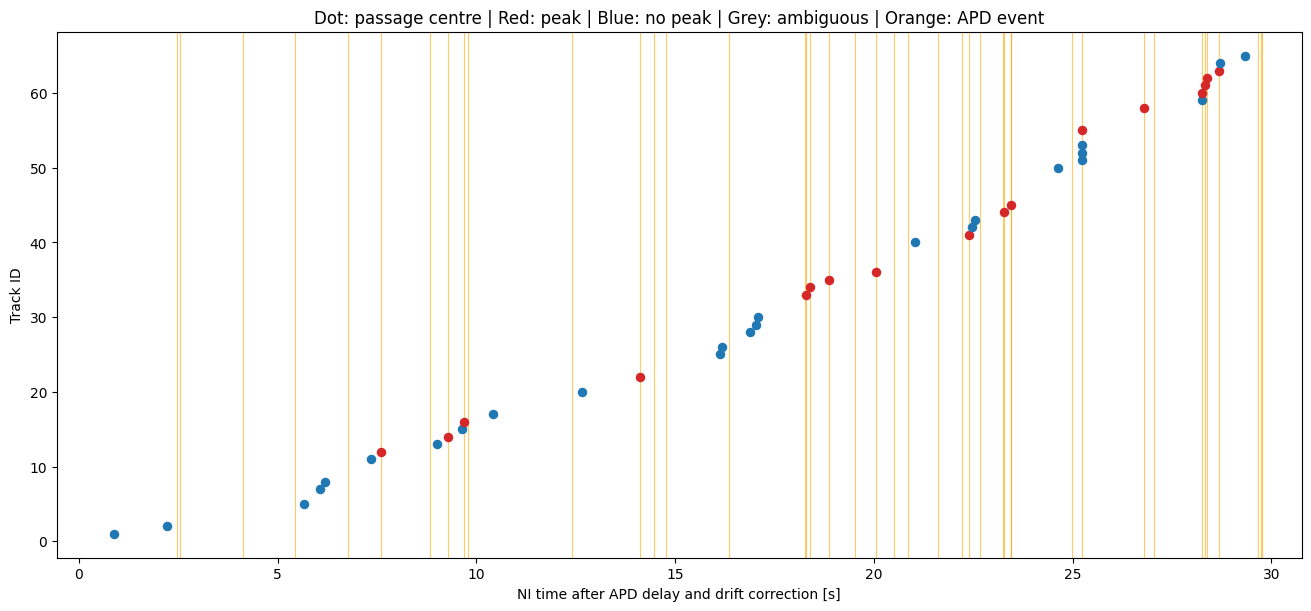

In [7]:
category_summary, peak_summary = assignment_summary(cells_final, peaks_current)
display(category_summary)
display(peak_summary)

review_mask = (
    cells_final["category"].eq("uneindeutig")
    | cells_final["quality_notes"].fillna("").str.contains(
        "multiple_peak_candidates|shared_peak_candidate|candidate_assigned_elsewhere"
    )
)
review_columns = [
    "track_id", "category", "reason", "blocking_reason",
    "quality_notes", "peak_ids", "candidate_peak_ids",
    "assignment_distance_ms",
]
display(cells_final.loc[review_mask, review_columns])

assignment_figure = plot_assignments(cells_final, peaks_current)
display(assignment_figure)
plt.close(assignment_figure)

## Inspect nearby or fragmented tracks

The review table identifies simultaneous close detections and sequential tracks that may belong to one biological cell. These are review candidates only; no tracks are merged automatically. Select a case ID to show annotated source frames. Set `CREATE_GIF = True` to save and display a slowed animation.

Suspicious cases: 5


,case_id,case_track_ids,case_types,pair_count,first_review_frame,minimum_distance_px
0,0,70;71,simultaneous_close,1,330297,28.356039
1,1,73;74,simultaneous_close,1,330301,25.172265
2,2,121;122,simultaneous_close,1,626814,26.908093
3,3,150;151;152,possible_track_split,2,903053,15.616903
4,4,253;254,simultaneous_close,1,2092718,29.130227


,case_id,case_track_ids,case_type,track_a,track_b,track_a_category,track_b_category,passage_delta_ms,common_frames,frame_gap,spatial_distance_px,area_ratio,review_frame,review_start_frame,review_end_frame
0,0,70;71,simultaneous_close,70,71,zelltyp_2_kein_peak,zelltyp_2_kein_peak,0.007143,6,0,28.356039,1.061758,330297,330295,330299
1,1,73;74,simultaneous_close,73,74,zelltyp_2_kein_peak,zelltyp_2_kein_peak,0.014286,6,0,25.172265,1.076543,330301,330299,330303
2,2,121;122,simultaneous_close,121,122,zelltyp_2_kein_peak,zelltyp_2_kein_peak,0.014286,5,0,26.908093,1.146868,626814,626812,626816
3,3,150;151;152,possible_track_split,150,152,zelltyp_2_kein_peak,zelltyp_2_kein_peak,0.042857,0,2,21.579836,1.616236,903053,903051,903055
4,3,150;151;152,possible_track_split,151,152,zelltyp_2_kein_peak,zelltyp_2_kein_peak,0.028572,0,1,15.616903,1.859779,903054,903052,903056
5,4,253;254,simultaneous_close,253,254,zelltyp_1_peak,zelltyp_2_kein_peak,0.014286,6,0,29.130227,1.256329,2092718,2092716,2092720


,case_id,case_track_ids,case_type,track_a,track_b,track_a_category,track_b_category,passage_delta_ms,common_frames,frame_gap,spatial_distance_px,area_ratio,review_frame,review_start_frame,review_end_frame
1,1,73;74,simultaneous_close,73,74,zelltyp_2_kein_peak,zelltyp_2_kein_peak,0.014286,6,0,25.172265,1.076543,330301,330299,330303


,track_id,category,quality_notes,peak_ids,passage_center_s,crops_path
73,73,zelltyp_2_kein_peak,incomplete_passage,,4.819782,zelltyp_2_kein_peak/crops/cell_000073_frame_00...
74,74,zelltyp_2_kein_peak,incomplete_passage,,4.819768,zelltyp_2_kein_peak/crops/cell_000074_frame_00...


OSError: [Errno 5] Input/output error

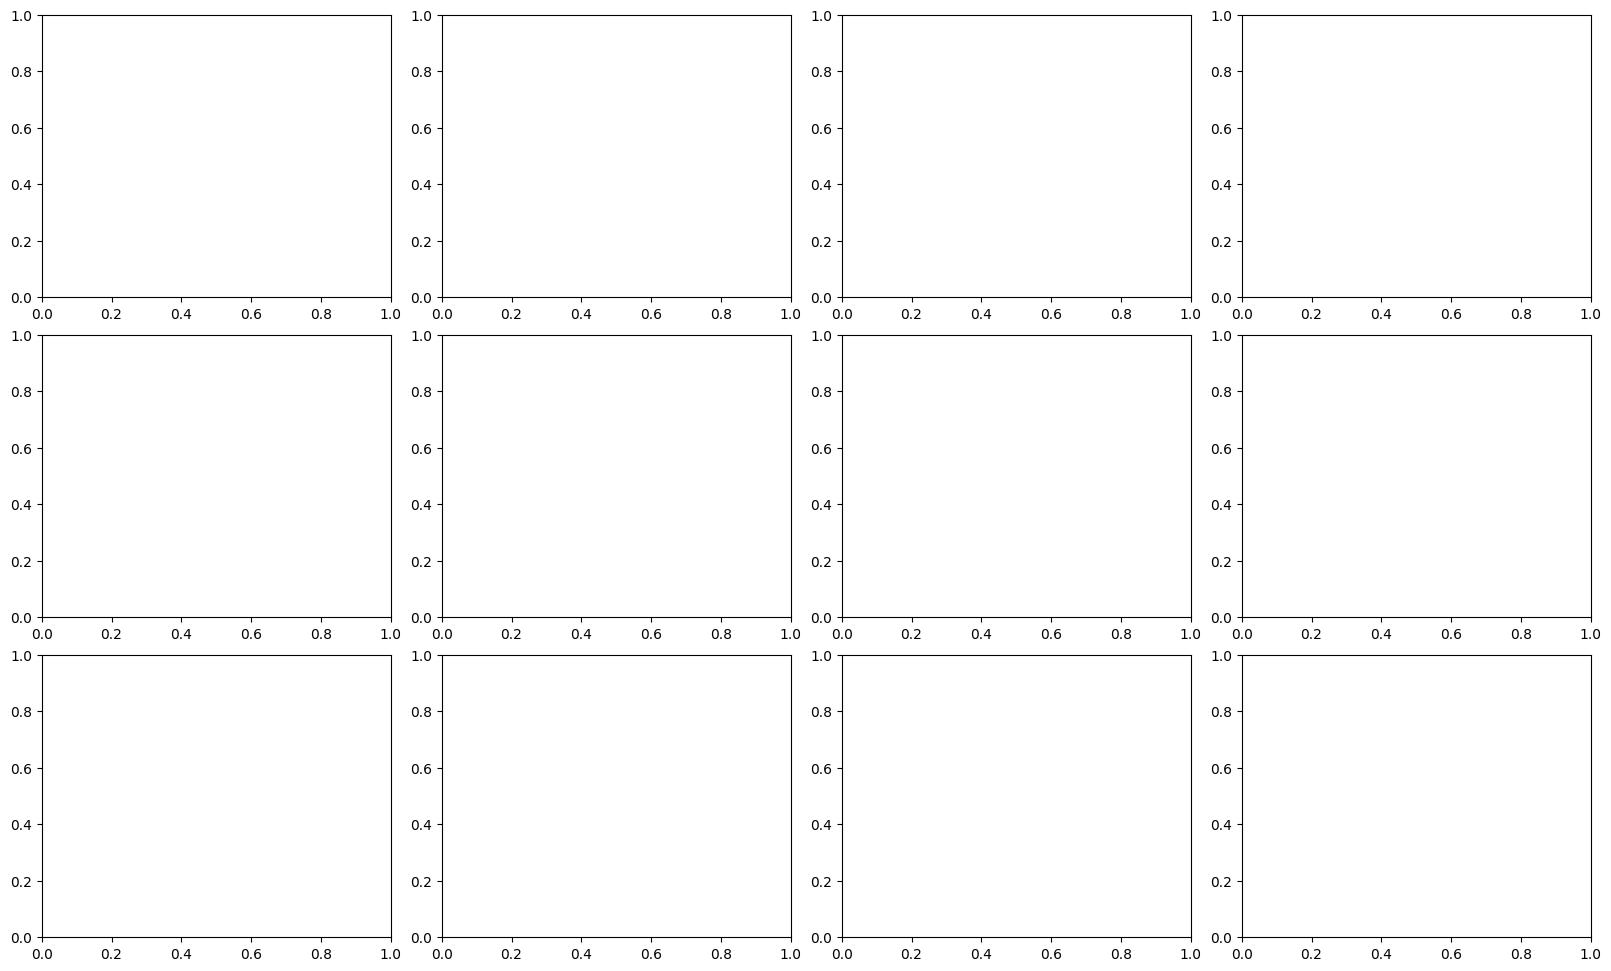

In [101]:
detections_current = pd.read_csv(run_dir / "detections.csv")
case_path = run_dir / "track_proximity_review.csv"
if case_path.exists():
    track_cases = pd.read_csv(case_path)
else:
    track_cases = pipeline.find_suspicious_track_cases(cells_final, detections_current, reclass_cfg if 'reclass_cfg' in globals() else cfg)
    track_cases.to_csv(case_path, index=False)

print(f"Suspicious cases: {track_cases['case_id'].nunique() if len(track_cases) else 0}")
if len(track_cases):
    case_summary = (
        track_cases.groupby(["case_id", "case_track_ids"], as_index=False)
        .agg(
            case_types=("case_type", lambda values: ";".join(sorted(set(values)))),
            pair_count=("case_type", "size"),
            first_review_frame=("review_frame", "min"),
            minimum_distance_px=("spatial_distance_px", "min"),
        )
    )
    display(case_summary)
    display(track_cases)

CASE_ID_TO_REVIEW = 1
CREATE_GIF = True

if CASE_ID_TO_REVIEW is not None:
    selected_pairs = track_cases.loc[track_cases["case_id"].eq(CASE_ID_TO_REVIEW)]
    selected_track_ids = sorted(
        set(selected_pairs["track_a"].astype(int))
        | set(selected_pairs["track_b"].astype(int))
    )
    display(selected_pairs)
    display(cells_final.loc[cells_final["track_id"].isin(selected_track_ids), [
        "track_id", "category", "quality_notes", "peak_ids",
        "passage_center_s", "crops_path",
    ]])
    case_figure = pipeline.plot_track_case(
        review_rec, detections_current, track_cases, CASE_ID_TO_REVIEW,
        context_frames=getattr(cfg, 'review_context_frames', 2),
    )
    display(case_figure)
    plt.close(case_figure)

    if CREATE_GIF:
        gif_path = pipeline.export_track_case_gif(
            review_rec, detections_current, track_cases, CASE_ID_TO_REVIEW,
            run_dir / "track_review_gifs" / f"case_{CASE_ID_TO_REVIEW:03d}.gif",
            context_frames=getattr(cfg, 'review_context_frames', 2), playback_fps=8,
        )
        display(DisplayImage(filename=str(gif_path)))
        print(f"Saved: {gif_path}")

### Save reviewed cases as ambiguous

Enter only the track IDs that cannot be assigned reliably. The decisions are stored in `manual_assignments.csv` and applied to `cells_final.csv`. Existing manual decisions are preserved.

In [ ]:
CASE_REVIEW_DECISIONS = {
    # 0: {
    #     "track_ids": [2, 3, 4, 5],
    #     "reason": "Cannot distinguish adjacent detections reliably",
    # },
}

if CASE_REVIEW_DECISIONS:
    pipeline = importlib.reload(pipeline)
    reviewed_updates = {}
    for case_id, decision in CASE_REVIEW_DECISIONS.items():
        selected = track_cases.loc[track_cases["case_id"].eq(int(case_id))]
        if selected.empty:
            raise ValueError(f"Case {case_id} does not exist.")
        case_tracks = set(selected["track_a"].astype(int)) | set(selected["track_b"].astype(int))
        chosen_tracks = [int(track_id) for track_id in decision["track_ids"]]
        invalid_tracks = sorted(set(chosen_tracks) - case_tracks)
        if invalid_tracks:
            raise ValueError(f"Tracks {invalid_tracks} do not belong to case {case_id}.")
        reason = str(decision["reason"]).strip()
        if not reason:
            raise ValueError(f"Case {case_id} requires a review reason.")
        for track_id in chosen_tracks:
            reviewed_updates[track_id] = ("uneindeutig", f"Case {case_id}: {reason}")

    manual_path = run_dir / "manual_assignments.csv"
    stored_assignments = {}
    if manual_path.exists():
        stored = pd.read_csv(manual_path)
        for row in stored.itertuples(index=False):
            if pd.isna(row.manual_category) or not str(row.manual_category).strip():
                continue
            saved_decision = (str(row.manual_category), str(row.manual_reason))
            if hasattr(row, "peak_id") and pd.notna(row.peak_id):
                saved_decision += (int(row.peak_id),)
            stored_assignments[int(row.track_id)] = saved_decision

    stored_assignments.update(reviewed_updates)
    cells_final = pipeline.apply_manual_assignments(
        cells_current, peaks_current, stored_assignments, rec=None
    )
    cells_final.to_csv(run_dir / "cells_final.csv", index=False)

    manual_rows = [
        {
            "track_id": track_id,
            "manual_category": decision[0],
            "manual_reason": decision[1],
            "peak_id": decision[2] if len(decision) == 3 else np.nan,
        }
        for track_id, decision in sorted(stored_assignments.items())
    ]
    pd.DataFrame(
        manual_rows,
        columns=["track_id", "manual_category", "manual_reason", "peak_id"],
    ).to_csv(manual_path, index=False)
    display(cells_final.loc[cells_final["track_id"].isin(reviewed_updates), [
        "track_id", "automatic_category", "category",
        "manual_category", "manual_reason", "peak_ids",
    ]])
    print(f"Updated: {run_dir / 'cells_final.csv'}")
else:
    print("No case decisions entered; cells_final.csv was not changed.")

track_id                                                7
category                              zelltyp_2_kein_peak
reason                    tracking_gap;incomplete_passage
blocking_reason                                          
quality_notes             tracking_gap;incomplete_passage
peak_ids                                                 
candidate_peak_ids                                       
assignment_distance_ms                                NaN
Name: 7, dtype: object

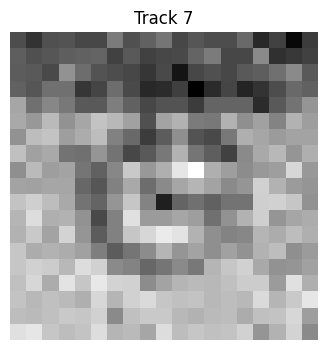

In [94]:
TRACK_TO_REVIEW = 7
if TRACK_TO_REVIEW is not None:
    row = cells_final.loc[cells_final["track_id"].eq(TRACK_TO_REVIEW)].iloc[0]
    display(row[review_columns])
    crop = tifffile.imread(run_dir / row["crops_path"])
    plt.figure(figsize=(4, 4))
    plt.imshow(crop, cmap="gray")
    plt.title(f"Track {TRACK_TO_REVIEW}")
    plt.axis("off")
    plt.show()

In [ ]:
if ("review_rec" in globals() and
        ("rec" not in globals() or review_rec is not rec)):
    review_rec.close()
if "rec" in globals():
    rec.close()